# Lab 4 - Partea 1: datele si retelele fully connected

In acest notebook:
1. **Datele**: cate clase, cate imagini pe clasa, ce dimensiuni au pozele originale.
2. **Experimentul de baza** (`baseline`): reteaua neuronala de baza din `lab4_common.DEFAULT_CONFIG`. Este referinta pentru toata echipa.
3. **Augmentarea**: aceeasi retea, cu si fara augmentare.
4. **Rezolutia**: aceeasi retea pe imagini 32 x 32, 64 x 64 si 96 x 96 (compromis viteza / calitate).
5. **Retele fully connected** (0 straturi convolutionale): 1-3 straturi ascunse, diferite numere de neuroni si functii de activare.
6. **De ce o retea fully connected e slaba la imagini.**

Toate experimentele folosesc aceleasi 5 fold-uri si acelasi mod de antrenare (`lab4_common.run_experiment`).
Daca rularea se intrerupe, la rularea urmatoare experimentele (si fold-urile) deja terminate se sar.

## Configurarea

**Ce face celula:** gasim radacina proiectului (folderul cu `pyproject.toml`), ca notebook-ul sa functioneze indiferent de unde este rulat,
si adaugam folderul `src` la cautarea modulelor, ca sa putem importa `lab4_common` (codul comun al echipei).
Importam bibliotecile folosite si alegem device-ul: `cuda` daca exista placa video, altfel `cpu`.

In [1]:
import sys
import json
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import f1_score
import lab4_common

device = lab4_common.get_device()
print("device:", device)

device: cpu


## 1. Datele

### 1.1 Clasele si numarul de imagini

**Ce face celula:** `list_images()` face un tabel cu toate pozele (calea, clasa si eticheta 0 - 4).
`value_counts()` numara pozele din fiecare clasa, iar graficul cu bare le arata, cu linia punctata la media pe clasa.
La final calculam de cate ori este mai mare clasa cea mai mare decat cea mai mica.

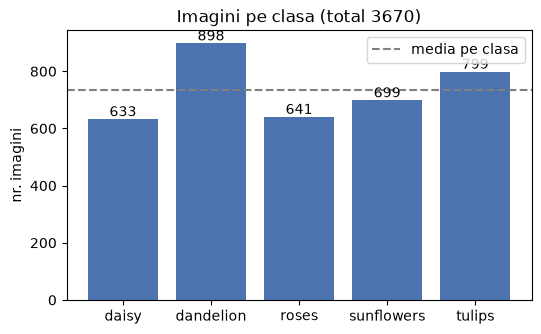

Raport clasa cea mai mare / cea mai mica: 1.42


In [2]:
df = lab4_common.list_images()
counts = df["class"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values, color="#4C72B0")
ax.axhline(len(df) / len(counts), color="gray", ls="--", label="media pe clasa")
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set(ylabel="nr. imagini", title=f"Imagini pe clasa (total {len(df)})")
ax.legend()
plt.show()

print(f"Raport clasa cea mai mare / cea mai mica: {counts.max() / counts.min():.2f}")

Sunt 5 clase si 3670 de imagini. Clasele nu sunt perfect egale: **dandelion** are cele mai multe poze (898),
**daisy** cele mai putine (633), adica de aproximativ 1.4 ori mai putine.
Dezechilibrul este mic, deci nu e nevoie de ponderi pe clase sau de oversampling, dar:
- folosim **macro-F1** (media F1 pe clase, fiecare clasa conteaza la fel), nu doar acuratetea;
- fold-urile sunt **stratificate**, ca fiecare fold sa aiba aceleasi proportii de clase.

### 1.2 Dimensiunile pozelor originale

Citim doar dimensiunea fiecarei poze (fara sa incarcam imaginea), ca sa vedem cat de mari si de ce forma sunt.

**Ce face celula:** pentru fiecare poza, `Image.open(...).size` citeste doar latimea si inaltimea (fara sa decodeze toata imaginea, deci e rapid).
Calculam si raportul latime / inaltime (peste 1 = poza "landscape", sub 1 = "portrait"), afisam statisticile (`describe`)
si un grafic cu un punct pentru fiecare poza, colorat dupa clasa.

,latime,inaltime,raport
count,3670.00,3670.00,3670.00
mean,365.06,271.79,1.33
std,116.89,51.74,0.29
min,143.00,159.00,0.60
25%,320.00,240.00,1.26
50%,320.00,240.00,1.34
75%,500.00,333.00,1.50
max,1024.00,442.00,5.48


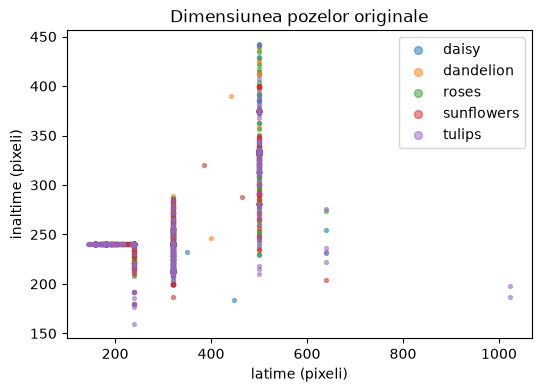

In [3]:
sizes = pd.DataFrame(
    [Image.open(lab4_common.DATA_DIR / p).size for p in df["path"]], columns=["latime", "inaltime"]
)
sizes["class"] = df["class"]
sizes["raport"] = sizes["latime"] / sizes["inaltime"]

display(sizes[["latime", "inaltime", "raport"]].describe().round(2))

fig, ax = plt.subplots(figsize=(6, 4))
for cls, g in sizes.groupby("class"):
    ax.scatter(g["latime"], g["inaltime"], s=8, alpha=0.5, label=cls)
ax.set(xlabel="latime (pixeli)", ylabel="inaltime (pixeli)", title="Dimensiunea pozelor originale")
ax.legend(markerscale=2)
plt.show()

Pozele **nu au aceeasi dimensiune**: cea mai frecventa este 320 x 240 (mediana), multe au latura mare de 500 de pixeli,
iar cea mai mare are 1024 de pixeli latime. Si forma difera: aproximativ 82% sunt "landscape" (latimea mai mare decat inaltimea),
13% sunt "portrait" si doar 6% sunt patrate.

O retea are nevoie de intrari de aceeasi marime, asa ca in `lab4_common` fiecare poza este:
1. taiata la un **patrat din centru** (floarea este de obicei in centru, iar asa nu se deformeaza imaginea);
2. **micsorata** la `img_size x img_size` (implicit 64 x 64).

O poza de 320 x 240 are 76.800 de pixeli x 3 canale = peste 230.000 de valori; la 64 x 64 raman 12.288 de valori.
Asta face antrenarea mult mai rapida si permite tinerea tuturor imaginilor in memorie. In sectiunea 4 verificam cat pierdem din calitate.

### 1.3 Cum arata pozele dupa micsorare

**Ce face celula:** alegem cate 2 poze din fiecare clasa si le afisam la cele 3 rezolutii pe care le testam (32, 64 si 96 de pixeli).
`load_dataset(size)` intoarce toate imaginile deja micsorate (din cache), asa ca vedem exact ce primeste reteaua.
Fiecare coloana este aceeasi poza, fiecare rand o rezolutie.

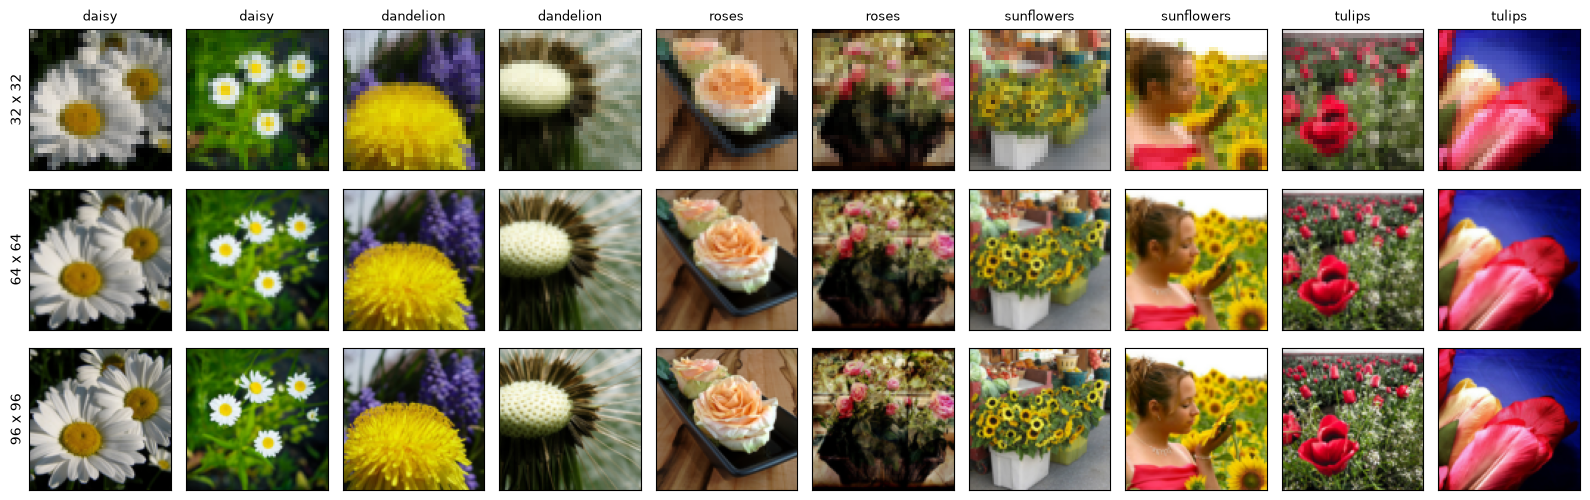

In [4]:
examples = df.groupby("class").sample(2, random_state=0)
small = {size: lab4_common.load_dataset(size)[1] for size in [32, 64, 96]}   # imaginile micsorate (din cache)

fig, axes = plt.subplots(3, 10, figsize=(16, 5.2))
for j, (i, row) in enumerate(examples.iterrows()):
    for r, size in enumerate([32, 64, 96]):
        axes[r, j].imshow(small[size][i].permute(1, 2, 0).numpy())
        axes[r, j].set_xticks([])
        axes[r, j].set_yticks([])
        if r == 0:
            axes[r, j].set_title(row["class"], fontsize=9)
        if j == 0:
            axes[r, j].set_ylabel(f"{size} x {size}")
plt.tight_layout()
plt.show()

La 32 x 32 florile inca se recunosc dupa culoare si forma generala, dar detaliile (petale, centrul florii) se pierd.
La 64 x 64 si 96 x 96 detaliile sunt vizibile. Diferenta dintre 64 si 96 este mica pentru ochi, dar 96 x 96 are de 2.25 ori mai multi pixeli.

## Functii ajutatoare pentru acest notebook

- `run_all(experimente)` ruleaza o lista de experimente (fiecare = numele + modificarile fata de configurarea de baza);
- `show_experiment(name)` deseneaza pentru un experiment: loss si macro-F1 pe epoci (train vs validare, media pe cele 5 fold-uri) si matricea de confuzie;
- `table(names)` arata rezultatele principale ale experimentelor intr-un tabel.

**Ce face celula:** doar defineste cele 3 functii (nu ruleaza nimic). `COLUMNS` sunt coloanele din jurnal pe care le afisam in tabele:
macro-F1 de validare (media si abaterea pe cele 5 fold-uri), F1 pe train, acuratetea, epoca la care a fost cel mai bun modelul,
timpul total de antrenare, numarul de parametri si marimea modelului pe disc.

In [5]:
def run_all(experiments, base=None):
    for name, changes in experiments.items():
        cfg = lab4_common.make_config(**{**(base or {}), **changes, "name": name})
        lab4_common.run_experiment(cfg, verbose=False)


def show_experiment(name):
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1, 0.9]})
    lab4_common.plot_history(name, ax=axes[:2])
    lab4_common.plot_confusion(name, ax=axes[2])
    plt.show()


COLUMNS = ["name", "val_f1_mean", "val_f1_std", "train_f1_mean", "val_acc_mean", "best_epoch_mean",
           "train_minutes_total", "n_params", "model_mb"]


def table(names):
    log = lab4_common.load_log().set_index("name").loc[names].reset_index()
    return log[COLUMNS].round(3)

## 2. Experimentul de baza (`baseline`)

Reteaua convolutionala de baza: 3 straturi convolutionale (32, 64, 128 filtre, kernel 3 x 3, ReLU, max-pooling 2 x 2),
un strat ascuns de 128 de neuroni, imagini 64 x 64, cu augmentare, Adam cu learning rate 0.001, maxim 30 de epoci, early stopping cu patience 5.

**Ce face celula:** `run_all` antreneaza reteaua de baza pe cele 5 fold-uri (antrenare pe 4, validare pe al 5-lea, de 5 ori)
si salveaza rezultatele in `results/lab4/runs/baseline/`. Daca experimentul a fost deja rulat, se sare si se citesc doar rezultatele.
Tabelul arata rezultatul mediu pe cele 5 fold-uri.

In [6]:
run_all({"baseline": {}})
table(["baseline"])

[baseline] gata: macro-F1 = 0.747 ± 0.016


,name,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,baseline,0.747,0.016,0.819,0.752,20.0,23.364,1142597,4.363


**Ce face celula:** `show_experiment` deseneaza cele 3 grafice pentru `baseline`: loss-ul si macro-F1 pe fiecare epoca
(linia albastra = train, cea portocalie = validare, media pe cele 5 fold-uri) si matricea de confuzie,
facuta din predictiile de validare ale tuturor fold-urilor (deci fiecare poza apare o singura data, cand a fost in validare).

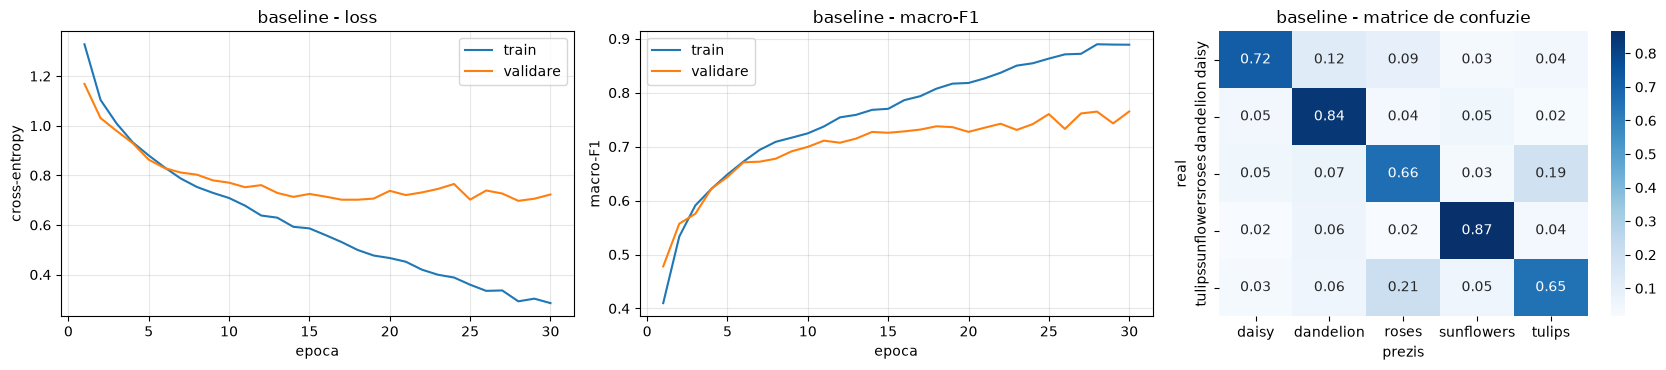

In [7]:
show_experiment("baseline")

**Interpretare - `baseline` (macro-F1 = 0.747 ± 0.016)**

*Loss (stanga).* In primele ~5 epoci loss-ul de train si cel de validare scad impreuna (de la ~1.3 la ~0.87):
reteaua invata lucruri generale despre flori, valabile si pe pozele pe care nu le-a vazut.
Dupa epoca ~10 curbele se despart: loss-ul de train continua sa scada pana la ~0.3, dar cel de validare ramane in jur de 0.7
(minimul, 0.70, e atins abia spre final). Diferenta dintre ele inseamna **overfitting**: reteaua incepe sa invete pe de rost pozele de antrenare.

*Macro-F1 (mijloc).* Aceeasi poveste: train urca pana la ~0.89, validarea se opreste la ~0.75 - 0.77.
Diferenta de ~0.12 este overfitting-ul. F1 de validare mai creste putin chiar si cand loss-ul de validare nu mai scade:
loss-ul penalizeaza mult greselile facute "cu mare incredere", in timp ce F1 numara doar cate predictii sunt corecte.
Reteaua greseste pe cam tot atatea poze, dar devine mai sigura pe ea si cand greseste.

Curbele sunt media pe cele 5 fold-uri. Fiecare fold se opreste la alta epoca (early stopping, in medie dupa 25 de epoci;
cea mai buna epoca este in medie a 20-a), asa ca spre final media se face pe mai putine fold-uri si curbele sunt mai "zgomotoase".

*Matricea de confuzie (dreapta).* Pe randuri este clasa reala, pe coloane clasa prezisa (fiecare rand insumeaza 1).
- **sunflowers (0.87)** si **dandelion (0.84)** sunt recunoscute cel mai bine: forma si culoarea galbena sunt foarte caracteristice;
- **daisy (0.72)** este confundata mai ales cu dandelion (12%): ambele au centrul galben si petale subtiri in jur;
- **roses (0.66)** si **tulips (0.65)** sunt cele mai grele si se confunda **intre ele** (19% si 21%):
  au culori asemanatoare (rosu, roz), iar la 64 x 64 se pierde o parte din diferenta de forma a petalelor.

## 3. Augmentarea: cu vs fara

Aceeasi retea de baza, antrenata o data cu augmentare (`baseline`) si o data fara (`baseline_noaug`).

**Ce face celula:** ruleaza aceeasi retea cu `augment=False` (singura diferenta fata de `baseline`) si pune cele doua experimente unul langa altul in tabel.

In [8]:
run_all({"baseline_noaug": {"augment": False}})
table(["baseline", "baseline_noaug"])

[baseline_noaug] gata: macro-F1 = 0.684 ± 0.009


,name,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,baseline,0.747,0.016,0.819,0.752,20.0,23.364,1142597,4.363
1,baseline_noaug,0.684,0.009,0.835,0.689,9.2,13.722,1142597,4.363


**Ce face celula:** aceleasi 3 grafice (loss, macro-F1, matricea de confuzie) pentru reteaua antrenata fara augmentare.

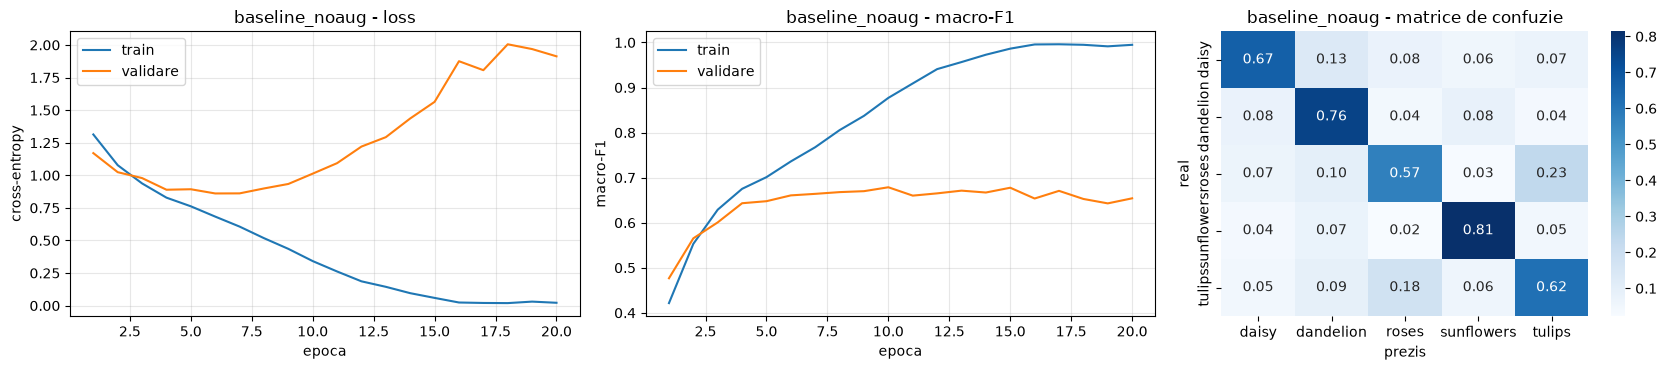

In [9]:
show_experiment("baseline_noaug")

**Interpretare - augmentarea (cu: 0.747, fara: 0.684)**

Fara augmentare reteaua invata pe de rost pozele de antrenare foarte repede:
- loss-ul de train scade aproape de 0 (0.02), iar F1 pe train ajunge la 0.995, adica aproape toate pozele de antrenare sunt "stiute";
- loss-ul de validare are minimul deja la epoca ~6 (0.86) si apoi **creste** pana la ~1.9: reteaua devine tot mai sigura pe predictii gresite;
- early stopping opreste antrenarea dupa ~14 epoci (fata de ~25 cu augmentare), iar cea mai buna epoca este in medie a 9-a.

In matricea de confuzie toate clasele sunt mai slabe decat la `baseline` (de ex. dandelion 0.76 fata de 0.84, roses 0.57 fata de 0.66),
iar confuziile sunt aceleasi: roses <-> tulips si daisy -> dandelion.

**Concluzie:** augmentarea aduce ~0.06 macro-F1 si intarzie overfitting-ul. Cu numai ~2900 de poze de antrenare pe fold,
reteaua are nevoie de variantele modificate (oglindite, mutate, cu alta luminozitate) ca sa invete ce este floarea, nu cum arata exact fiecare poza.
De aceea augmentarea ramane in configurarea de baza pentru toata echipa.

## 4. Rezolutia: 32 x 32, 64 x 64, 96 x 96

Aceeasi retea de baza, pe imagini de marimi diferite. Ne intereseaza compromisul dintre calitate (macro-F1) si timp.
Numarul de parametri creste cu rezolutia, pentru ca harta de trasaturi de la ultimul strat convolutional (care intra in stratul fully connected) e mai mare.

**Ce face celula:** ruleaza reteaua de baza pe imagini de 32 x 32 (`res32`) si 96 x 96 (`res96`); rezultatul pentru 64 x 64 este chiar `baseline`.
Tabelul le pune pe toate trei impreuna, cu o coloana in plus pentru rezolutie.

In [10]:
run_all({"res32": {"img_size": 32}, "res96": {"img_size": 96}})
res = table(["res32", "baseline", "res96"])
res.insert(1, "img_size", [32, 64, 96])
res

[res32] gata: macro-F1 = 0.740 ± 0.015
[res96] gata: macro-F1 = 0.765 ± 0.010


,name,img_size,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,res32,32,0.740,0.015,0.766,0.744,21.4,7.717,356165,1.362
1,baseline,64,0.747,0.016,0.819,0.752,20.0,23.364,1142597,4.363
2,res96,96,0.765,0.010,0.856,0.768,23.2,76.252,2453317,9.362


**Ce face celula:** doua grafice din tabelul de mai sus: stanga, macro-F1 pentru fiecare rezolutie (bara verticala = abaterea dintre fold-uri);
dreapta, timpul total de antrenare pe cele 5 fold-uri.

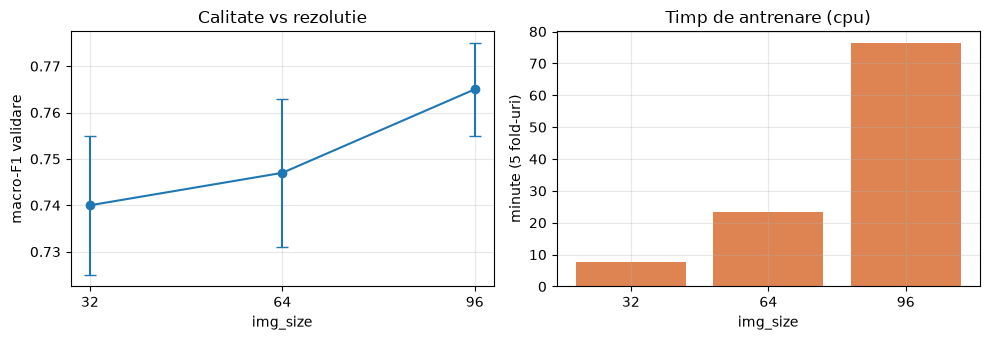

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].errorbar(res["img_size"], res["val_f1_mean"], yerr=res["val_f1_std"], marker="o", capsize=4)
axes[0].set(xlabel="img_size", ylabel="macro-F1 validare", title="Calitate vs rezolutie", xticks=[32, 64, 96])
axes[1].bar(res["img_size"].astype(str), res["train_minutes_total"], color="#DD8452")
axes[1].set(xlabel="img_size", ylabel="minute (5 fold-uri)", title=f"Timp de antrenare ({device})")
for a in axes:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretare - rezolutia**

| img_size | macro-F1 | timp (5 fold-uri, CPU) | parametri | MB pe disc |
|---|---|---|---|---|
| 32 x 32 | 0.740 ± 0.015 | 8 min | 0.36 M | 1.4 |
| 64 x 64 | 0.747 ± 0.016 | 23 min | 1.14 M | 4.4 |
| 96 x 96 | **0.765 ± 0.010** | 76 min | 2.45 M | 9.4 |

- Calitatea creste cu rezolutia, dar putin: de la 32 la 64 doar +0.007 (mai putin decat abaterea dintre fold-uri), de la 64 la 96 inca +0.018.
  Florile se recunosc mult dupa culoare si forma generala, care se vad si pe imagini mici.
- Timpul creste mult mai repede: fiecare strat convolutional lucreaza pe toti pixelii, iar 96 x 96 are de 2.25 ori mai multi pixeli decat 64 x 64
  (si de 9 ori mai multi decat 32 x 32). In plus, numarul de parametri creste, pentru ca harta de trasaturi care intra in stratul fully connected este mai mare.

**Concluzie:** 64 x 64 este compromisul bun pentru grid search (multe experimente, fiecare in ~20 de minute pe CPU).
96 x 96 merita incercat pentru modelul final, unde conteaza fiecare sutime de macro-F1 si timpul nu mai e o problema.

**Ce face celula:** graficele de loss, macro-F1 si matricea de confuzie pentru `res32` si `res96` (pentru 64 x 64 sunt cele de la `baseline`).

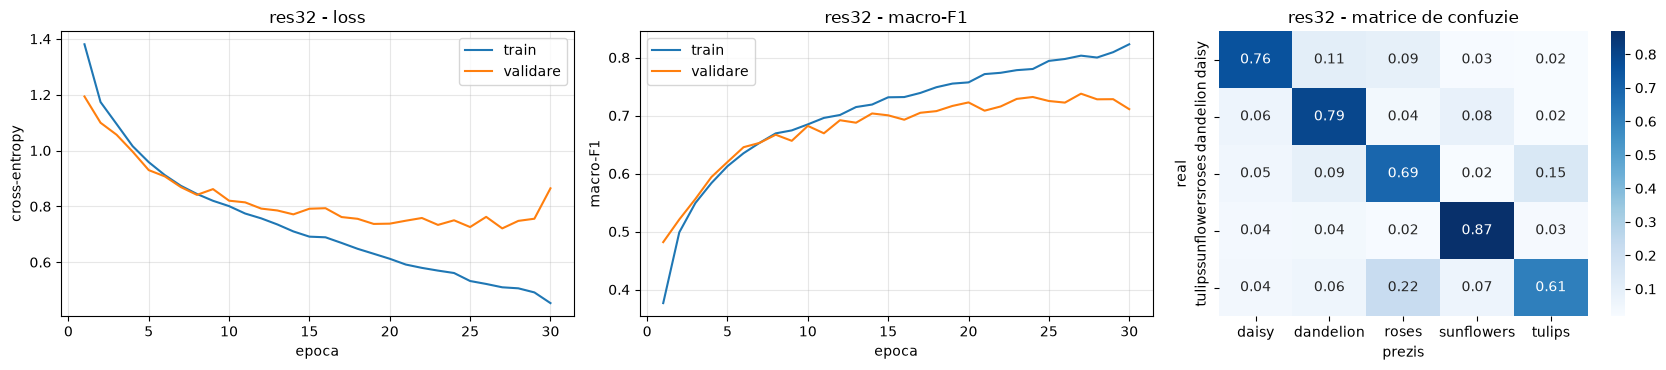

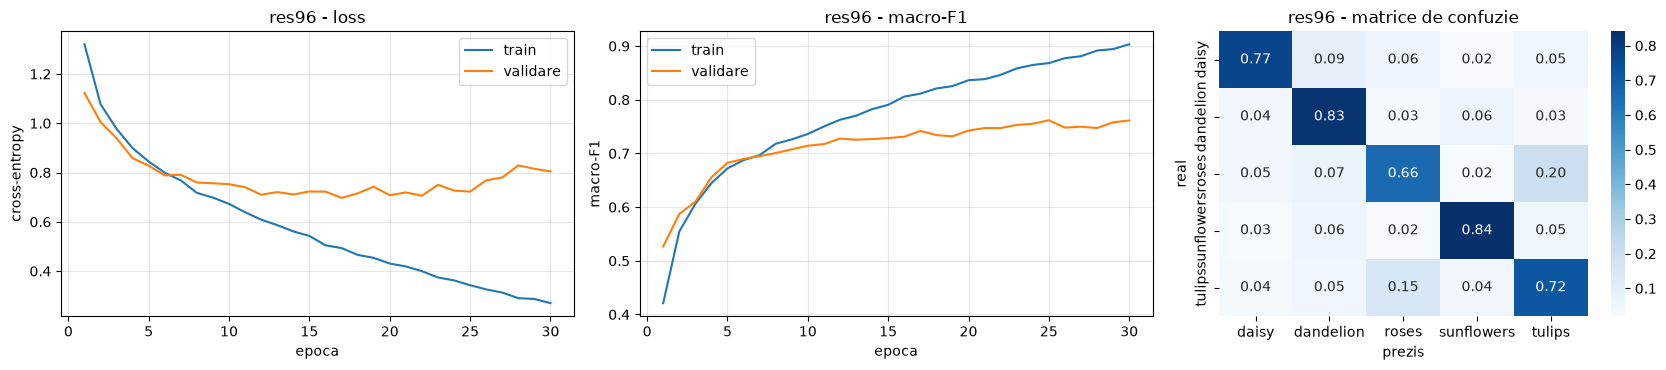

In [12]:
show_experiment("res32")
show_experiment("res96")

**Interpretare - curbele pentru 32 x 32 si 96 x 96**

- **res32:** curbele de train si validare raman mai apropiate decat la `baseline` (la final F1 0.82 pe train, 0.71 pe validare):
  pe imagini mici reteaua are mai putine detalii pe care sa le invete pe de rost, deci face mai putin overfitting, dar are si mai putina informatie.
  Tulips are cel mai mic scor (0.61), confundata cu roses in 22% din cazuri.
- **res96:** reteaua invata mai repede (F1 de validare 0.68 deja la epoca 5, fata de 0.64 la 64 x 64) si ajunge la valori mai mari,
  dar si diferenta fata de train este mare (0.90 pe train), deci face overfitting ca `baseline`.
  Cel mai mult castiga **tulips (0.72 fata de 0.65)** si daisy (0.77 fata de 0.72): detaliile petalelor ajuta la separarea florilor asemanatoare.
- La toate rezolutiile confuziile sunt aceleasi (roses <-> tulips, daisy -> dandelion), deci ele vin din asemanarea florilor, nu din rezolutie.

## 5. Retele fully connected (0 straturi convolutionale)

Fara straturi convolutionale, imaginea 64 x 64 x 3 este "intinsa" intr-un vector de 12.288 de valori, care intra direct in straturile fully connected.

Pornim de la o retea cu un strat ascuns de 256 de neuroni si ReLU (`fc_256`) si variem pe rand:
- **adancimea si latimea**: 1, 2 sau 3 straturi ascunse, cu 64 - 1024 de neuroni;
- **functia de activare** (pe reteaua cu 2 straturi, 256 si 128): ReLU, LeakyReLU, Tanh, GELU;
- **augmentarea**, si la reteaua fully connected.

Restul setarilor sunt ca la `baseline` (64 x 64, Adam, lr 0.001, early stopping).

**Ce face celula:** `FC = {"conv_layers": []}` scoate toate straturile convolutionale, deci imaginea intra direct in straturile fully connected.
Cele 3 dictionare descriu experimentele (numele -> ce se schimba): `fc_layers` este lista cu numarul de neuroni din fiecare strat ascuns
(de ex. `[256, 128]` = doua straturi, cu 256 si 128 de neuroni), iar `activation` este functia de activare.
`run_all(..., base=FC)` aplica aceeasi modificare de baza (fara convolutii) la toate experimentele si le ruleaza pe rand.

In [13]:
FC = {"conv_layers": []}

FC_SIZES = {
    "fc_64":          {"fc_layers": [64]},
    "fc_256":         {"fc_layers": [256]},
    "fc_1024":        {"fc_layers": [1024]},
    "fc_256_128":     {"fc_layers": [256, 128]},
    "fc_1024_256":    {"fc_layers": [1024, 256]},
    "fc_256_128_64":  {"fc_layers": [256, 128, 64]},
}
FC_ACTIVATIONS = {
    "fc_256_128_leaky": {"fc_layers": [256, 128], "activation": "leaky_relu"},
    "fc_256_128_tanh":  {"fc_layers": [256, 128], "activation": "tanh"},
    "fc_256_128_gelu":  {"fc_layers": [256, 128], "activation": "gelu"},
}
FC_OTHER = {
    "fc_256_noaug": {"fc_layers": [256], "augment": False},
}

run_all(FC_SIZES, base=FC)
run_all(FC_ACTIVATIONS, base=FC)
run_all(FC_OTHER, base=FC)

[fc_64] gata: macro-F1 = 0.538 ± 0.020
[fc_256] gata: macro-F1 = 0.543 ± 0.013
[fc_1024] gata: macro-F1 = 0.526 ± 0.017
[fc_256_128] gata: macro-F1 = 0.546 ± 0.028
[fc_1024_256] gata: macro-F1 = 0.550 ± 0.005
[fc_256_128_64] gata: macro-F1 = 0.533 ± 0.035
[fc_256_128_leaky] gata: macro-F1 = 0.538 ± 0.020
[fc_256_128_tanh] gata: macro-F1 = 0.474 ± 0.021
[fc_256_128_gelu] gata: macro-F1 = 0.544 ± 0.021
[fc_256_noaug] gata: macro-F1 = 0.496 ± 0.013


### 5.1 Adancimea si numarul de neuroni

**Ce face celula:** afiseaza rezultatele celor 6 retele cu marimi diferite (1 - 3 straturi ascunse, 64 - 1024 de neuroni).

In [14]:
table(list(FC_SIZES))

,name,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,fc_64,0.538,0.020,0.550,0.542,15.4,1.543,786821,3.004
1,fc_256,0.543,0.013,0.567,0.549,15.8,3.760,3147269,12.008
2,fc_1024,0.526,0.017,0.530,0.532,12.0,10.951,12589061,48.026
3,fc_256_128,0.546,0.028,0.601,0.548,18.0,4.399,3179525,12.132
4,fc_1024_256,0.550,0.005,0.576,0.554,15.4,12.967,12847621,49.013
5,fc_256_128_64,0.533,0.035,0.559,0.537,13.4,3.566,3187461,12.163


**Ce face celula:** cele 3 grafice (loss, macro-F1, matricea de confuzie) pentru fiecare dintre cele 6 retele, in ordinea din tabel.

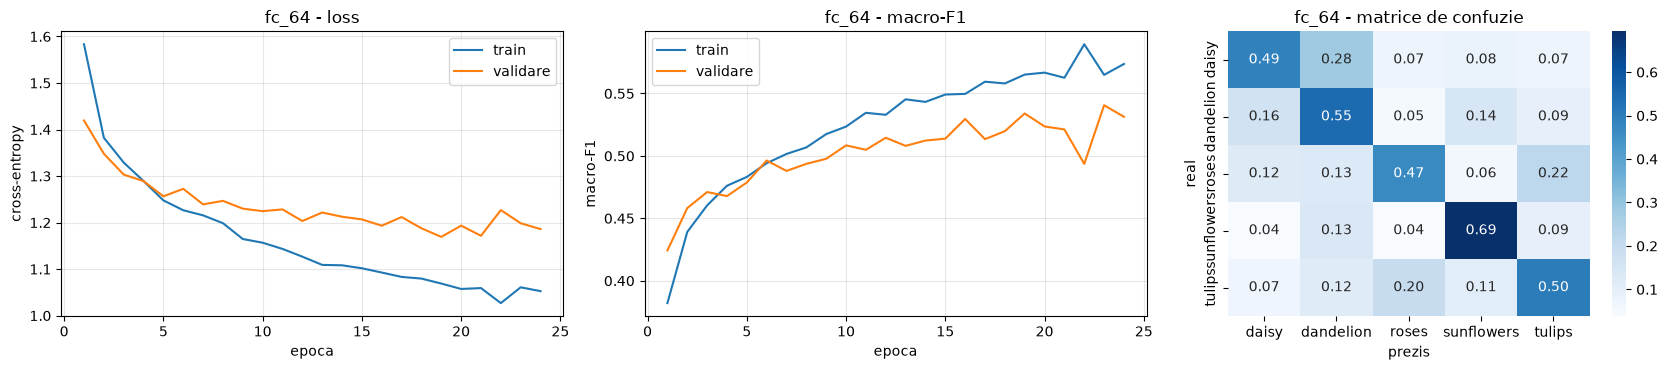

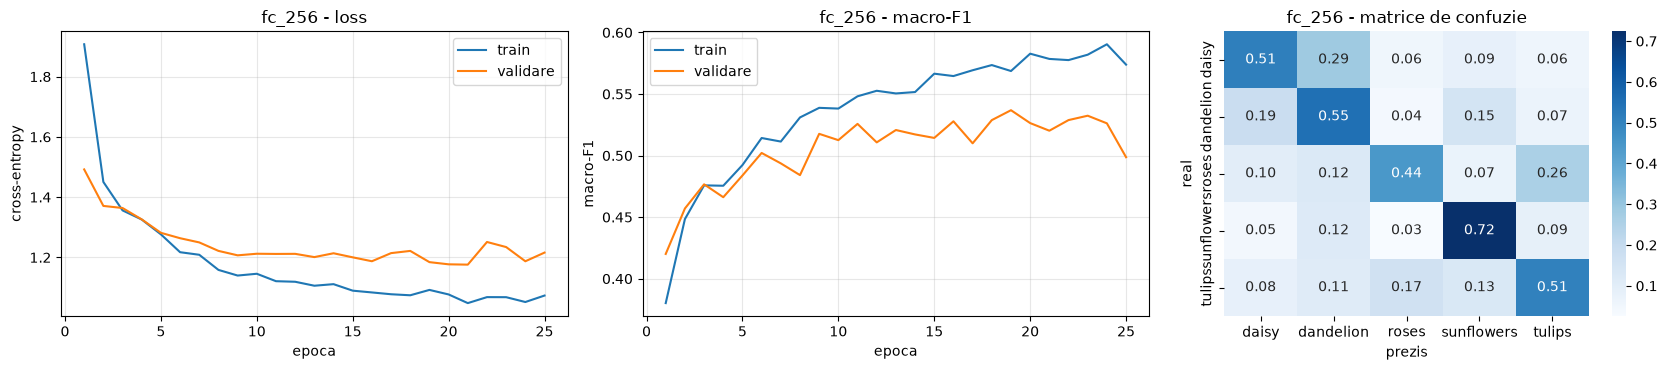

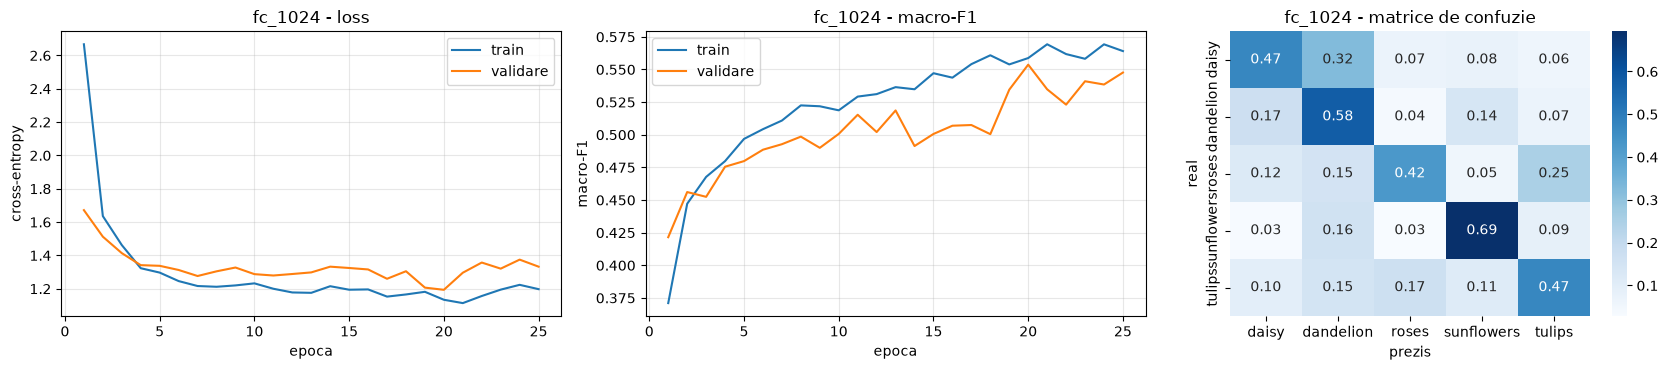

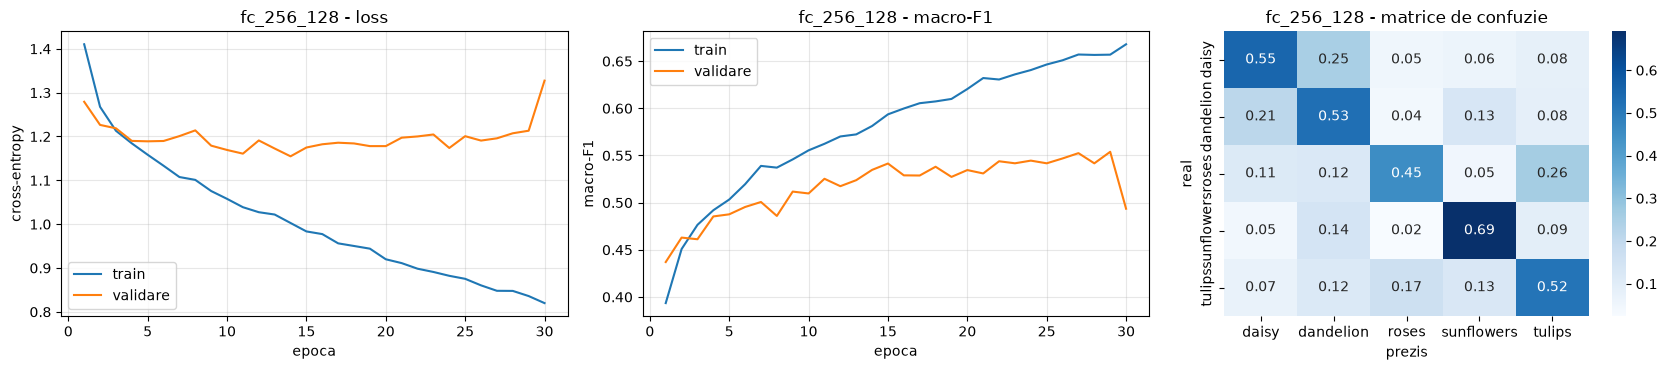

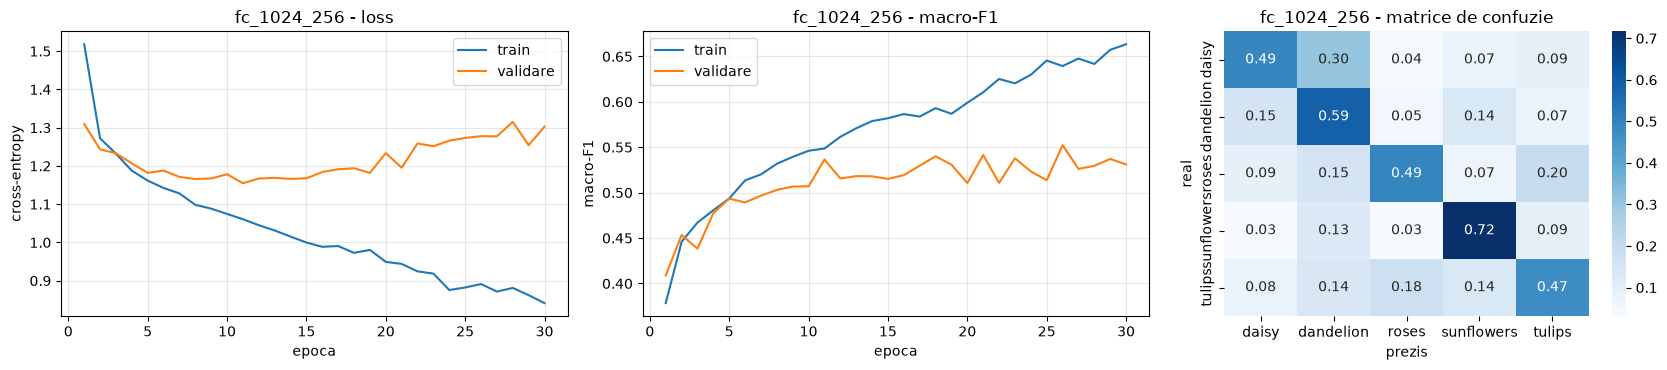

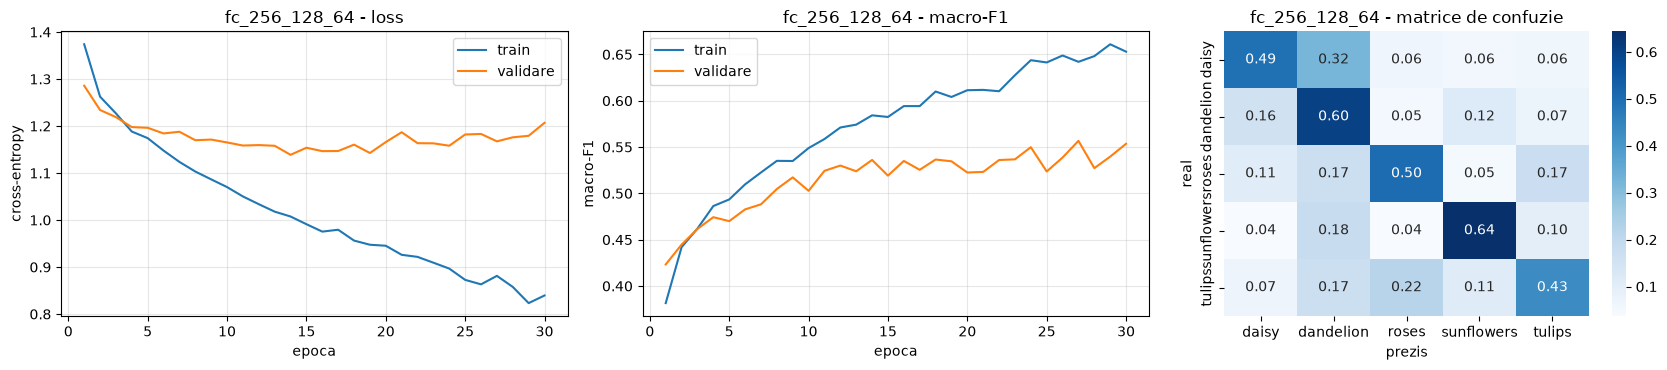

In [15]:
for name in FC_SIZES:
    show_experiment(name)

**Interpretare - adancimea si numarul de neuroni**

| retea | straturi ascunse | macro-F1 | parametri | MB pe disc |
|---|---|---|---|---|
| fc_64 | 64 | 0.538 ± 0.020 | 0.79 M | 3.0 |
| fc_256 | 256 | 0.543 ± 0.013 | 3.15 M | 12.0 |
| fc_1024 | 1024 | 0.526 ± 0.017 | 12.6 M | 48.0 |
| fc_256_128 | 256, 128 | 0.546 ± 0.028 | 3.18 M | 12.1 |
| fc_1024_256 | 1024, 256 | **0.550 ± 0.005** | 12.8 M | 49.0 |
| fc_256_128_64 | 256, 128, 64 | 0.533 ± 0.035 | 3.19 M | 12.2 |

- Toate retelele fully connected ajung la **0.53 - 0.55**, mult sub reteaua convolutionala de baza (0.747), desi au de 3 - 11 ori **mai multi** parametri.
- **Mai multi neuroni sau mai multe straturi nu ajuta:** diferentele dintre ele (cel mult 0.024) sunt de marimea abaterii dintre fold-uri.
  `fc_1024_256` are de 16 ori mai multi parametri decat `fc_64` pentru doar +0.012.
- Aproape toti parametrii sunt in primul strat: 12.288 de intrari (64 x 64 x 3) x numarul de neuroni. De aceea marimea pe disc creste aproape proportional cu primul strat.
- *Curbele:* F1 pe train ramane si el mic (~0.55 - 0.67), iar loss-ul scade lent (de la ~1.4 la ~1.1 - 1.2).
  Reteaua nu reuseste sa invete bine nici pozele de antrenare (cu augmentare): pixelii singuri, fara informatie despre vecinatate, sunt greu de folosit.
  La retelele cu 2 - 3 straturi loss-ul de validare are minimul la epoca ~11 - 14 si apoi creste usor, deci incepe overfitting-ul.
- *Matricele de confuzie:* doar **sunflowers** este recunoscuta in ~70% din cazuri. **daisy este confundata cu dandelion in 25 - 32% din cazuri**,
  mult mai des decat la reteaua convolutionala (12%), iar roses <-> tulips in 20 - 26%. Reteaua se bazeaza mai ales pe culori (galben, rosu), nu pe forma.

### 5.2 Functia de activare

**Ce face celula:** compara aceeasi retea (doua straturi ascunse, 256 si 128 de neuroni) cu patru functii de activare.
`fc_256_128` din sectiunea 5.1 este varianta cu ReLU, deci nu mai trebuie rulata din nou.

In [16]:
act = table(["fc_256_128", *FC_ACTIVATIONS])
act.insert(1, "activation", ["relu", "leaky_relu", "tanh", "gelu"])
act

,name,activation,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,fc_256_128,relu,0.546,0.028,0.601,0.548,18.0,4.399,3179525,12.132
1,fc_256_128_leaky,leaky_relu,0.538,0.020,0.572,0.548,14.2,3.961,3179525,12.132
2,fc_256_128_tanh,tanh,0.474,0.021,0.456,0.478,9.4,2.907,3179525,12.132
3,fc_256_128_gelu,gelu,0.544,0.021,0.596,0.551,16.4,4.720,3179525,12.132


**Ce face celula:** graficele pentru variantele cu LeakyReLU, Tanh si GELU (varianta cu ReLU, `fc_256_128`, este in sectiunea 5.1).

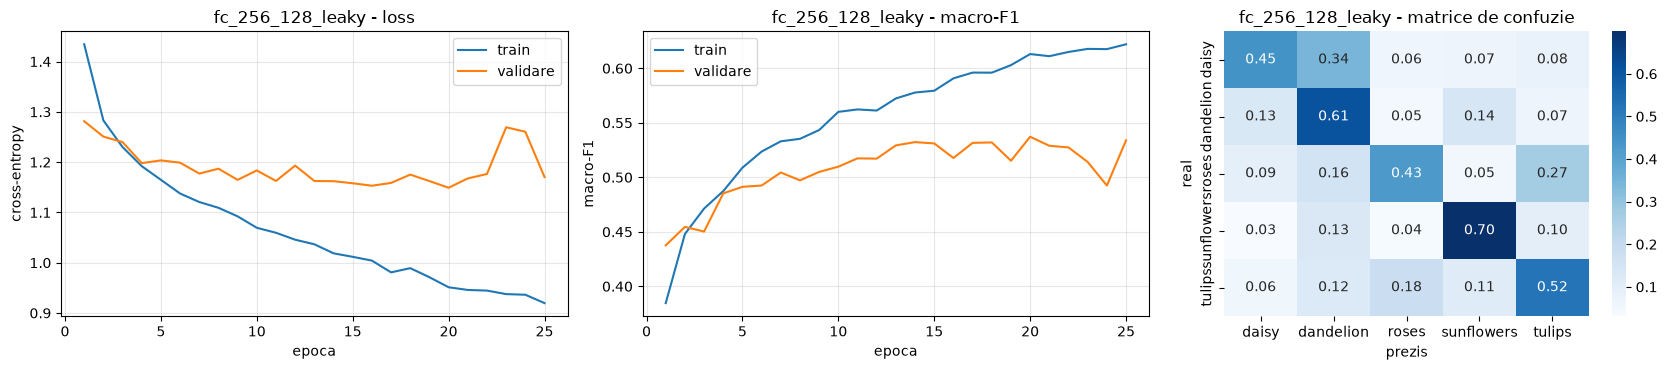

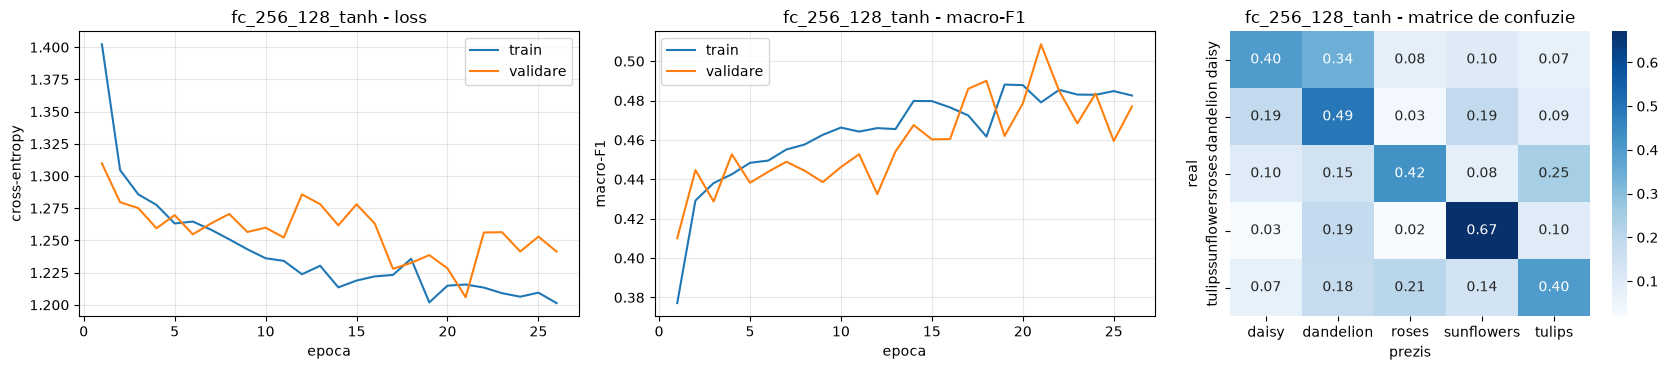

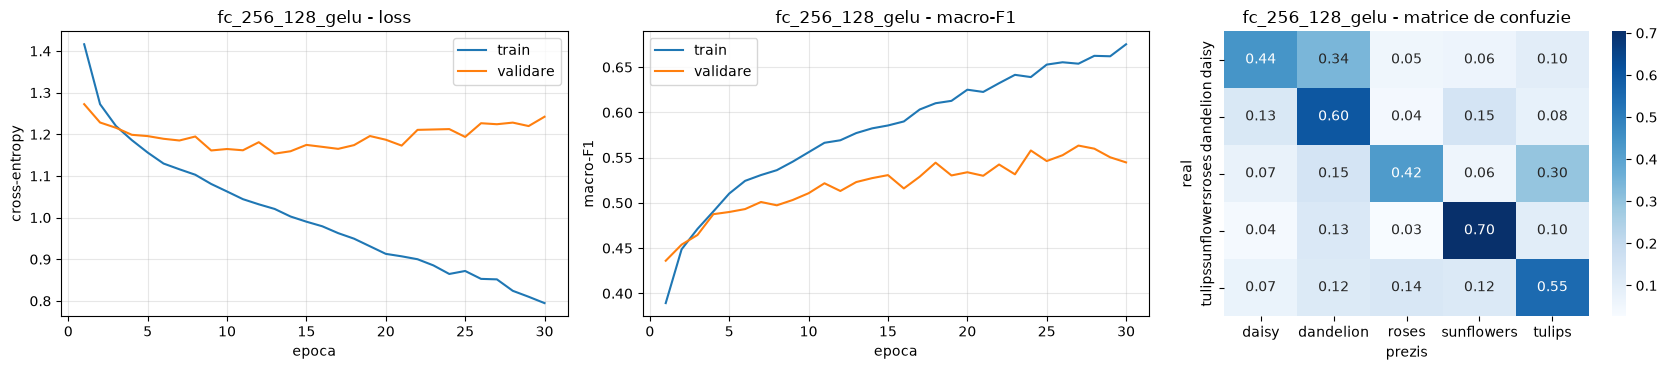

In [17]:
for name in FC_ACTIVATIONS:
    show_experiment(name)

**Interpretare - functia de activare** (aceeasi retea: 256 si 128 de neuroni)

- **ReLU (0.546), GELU (0.544) si LeakyReLU (0.538)** dau practic acelasi rezultat (diferente mai mici decat abaterea dintre fold-uri),
  iar curbele si matricele de confuzie arata la fel. GELU si LeakyReLU sunt variante "mai netede" ale lui ReLU si nu schimba nimic aici.
- **Tanh este cea mai slaba (0.474)**, iar F1 pe train este si el mic (0.456), deci reteaua nu reuseste sa invete nici pe datele de antrenare
  (loss-ul scade doar de la 1.40 la 1.20). Tanh "se satureaza": pentru valori mari (pozitive sau negative) iesirea ramane aproape constanta (1 sau -1),
  gradientul devine aproape 0 si greutatile se mai schimba foarte putin. Cu 12.288 de intrari pe neuron, sumele din primul strat sunt mari, deci saturarea apare des.
  In matricea de confuzie daisy si tulips sunt recunoscute doar in 40% din cazuri.

**Concluzie:** functia de activare conteaza putin, cu exceptia lui Tanh. ReLU ramane alegerea implicita (cea mai simpla si cea mai rapida).

### 5.3 Augmentarea la reteaua fully connected

**Ce face celula:** compara reteaua fully connected cu un strat de 256 de neuroni antrenata cu augmentare (`fc_256`) si fara (`fc_256_noaug`).

In [18]:
table(["fc_256", "fc_256_noaug"])

,name,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,fc_256,0.543,0.013,0.567,0.549,15.8,3.760,3147269,12.008
1,fc_256_noaug,0.496,0.013,0.832,0.501,7.8,2.479,3147269,12.008


**Ce face celula:** graficele pentru reteaua fully connected antrenata fara augmentare (cele cu augmentare, `fc_256`, sunt in sectiunea 5.1).

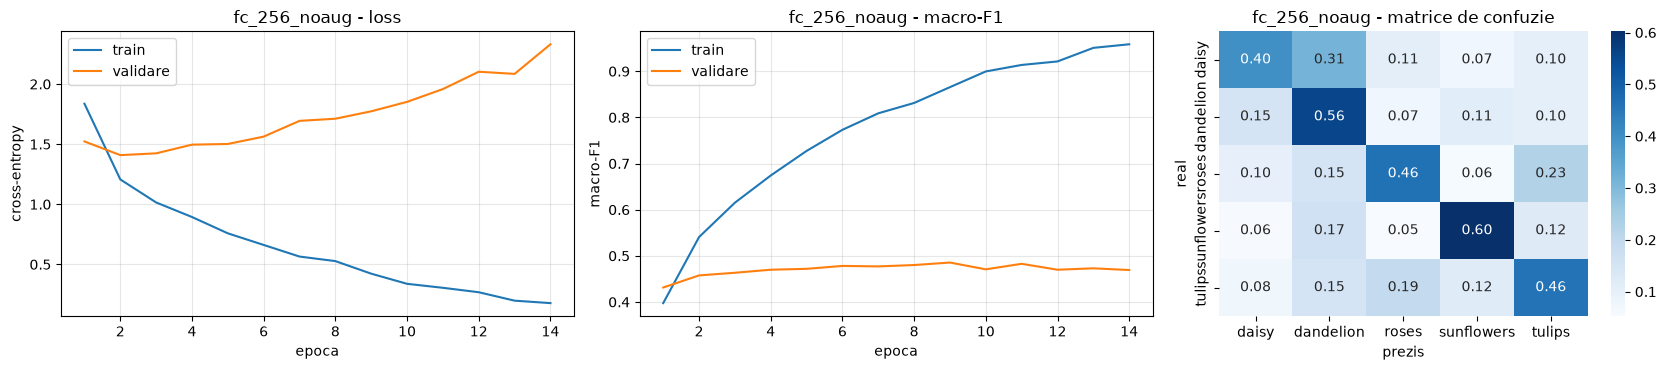

In [19]:
show_experiment("fc_256_noaug")

**Interpretare - fully connected fara augmentare (0.496, fata de 0.543 cu augmentare)**

Aici overfitting-ul este si mai puternic decat la reteaua convolutionala:
- F1 pe train creste pana la 0.96 si loss-ul de train scade la 0.18;
- loss-ul de validare are minimul deja la **epoca 2** si apoi creste pana la 2.3, iar F1 de validare ramane in jur de 0.47;
- early stopping opreste antrenarea dupa ~13 epoci.

Cu 3 milioane de parametri si doar ~2900 de poze, reteaua poate memora usor fiecare poza. Augmentarea ajuta si aici (+0.05),
dar nu rezolva problema de fond: o retea fully connected nu are nicio idee despre ce pixeli sunt vecini.

## 6. De ce o retea fully connected e slaba la imagini

### 6.1 Calitate vs numar de parametri

Fiecare punct este un experiment din acest notebook. Axa x (numarul de parametri) este logaritmica.

**Ce face celula:** `ALL` este lista tuturor experimentelor din aceasta parte. Din jurnal (`load_log`) luam aceste experimente si le impartim
in fully connected (`conv_layers == "[]"`) si convolutionale. Desenam macro-F1 fata de numarul de parametri, cu numele fiecarui experiment langa punct.
Tabelul de sub grafic are aceleasi valori.

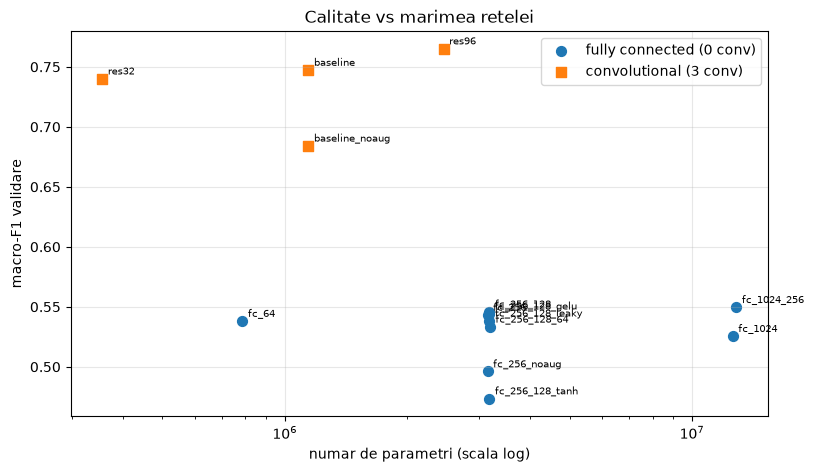

,name,val_f1_mean,n_params,model_mb,train_minutes_total
0,baseline,0.747,1142597,4.363,23.364
1,baseline_noaug,0.684,1142597,4.363,13.722
2,res32,0.740,356165,1.362,7.717
3,res96,0.765,2453317,9.362,76.252
4,fc_64,0.538,786821,3.004,1.543
5,fc_256,0.543,3147269,12.008,3.760
6,fc_1024,0.526,12589061,48.026,10.951
7,fc_256_128,0.546,3179525,12.132,4.399
8,fc_1024_256,0.550,12847621,49.013,12.967
9,fc_256_128_64,0.533,3187461,12.163,3.566


In [20]:
ALL = ["baseline", "baseline_noaug", "res32", "res96", *FC_SIZES, *FC_ACTIVATIONS, *FC_OTHER]
log = lab4_common.load_log().set_index("name").loc[ALL].reset_index()
is_fc = log["conv_layers"] == "[]"

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(log.loc[is_fc, "n_params"], log.loc[is_fc, "val_f1_mean"], s=50, label="fully connected (0 conv)")
ax.scatter(log.loc[~is_fc, "n_params"], log.loc[~is_fc, "val_f1_mean"], s=50, marker="s", label="convolutional (3 conv)")
for _, r in log.iterrows():
    ax.annotate(r["name"], (r["n_params"], r["val_f1_mean"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set(xlabel="numar de parametri (scala log)", ylabel="macro-F1 validare", title="Calitate vs marimea retelei")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

log[["name", "val_f1_mean", "n_params", "model_mb", "train_minutes_total"]].round(3)

**Interpretare - calitate vs numar de parametri**

Graficul se imparte clar in doua grupuri:
- **retelele convolutionale** (patrate) sunt toate sus, la **0.68 - 0.77**, cu 0.36 - 2.45 milioane de parametri;
- **retelele fully connected** (cercuri) sunt toate jos, la **0.47 - 0.55**, desi au intre 0.8 si 12.8 milioane de parametri (pana la 49 MB pe disc).

Deci nu numarul de parametri face diferenta, ci **modul in care sunt folositi**. Intr-un strat convolutional acelasi filtru mic (3 x 3)
este folosit in toate pozitiile imaginii, deci cu putini parametri se gasesc aceleasi tipare oriunde in poza.
Intr-o retea fully connected fiecare pixel are greutatea lui separata, asa ca majoritatea parametrilor se "consuma" pe pozitii, nu pe tipare.
In plus, retelele fully connected se antreneaza mai repede (1.5 - 13 minute fata de 8 - 76), dar timpul nu compenseaza diferenta de calitate.

### 6.2 Ce "vede" primul strat al unei retele fully connected

Fiecare neuron din primul strat ascuns are cate o greutate pentru fiecare pixel si canal (64 x 64 x 3 = 12.288 de greutati).
Putem desena aceste greutati ca pe o imagine: arata "sablonul" pe care il cauta neuronul in toata poza.
Folosim modelul `fc_256` salvat din fold-ul 0.

**Ce face celula:** `load_saved_model` reconstruieste reteaua dupa `config.json` si incarca greutatile salvate (`models/<nume>.pt`, modelul din fold-ul 0).
`model_fc.classifier[0].weight` sunt greutatile primului strat: o matrice 256 x 12.288. Fiecare rand (un neuron) il transformam inapoi
in forma unei imagini (3 x 64 x 64), il scalam intre 0 si 1 ca sa se poata desena si afisam primii 16 neuroni.

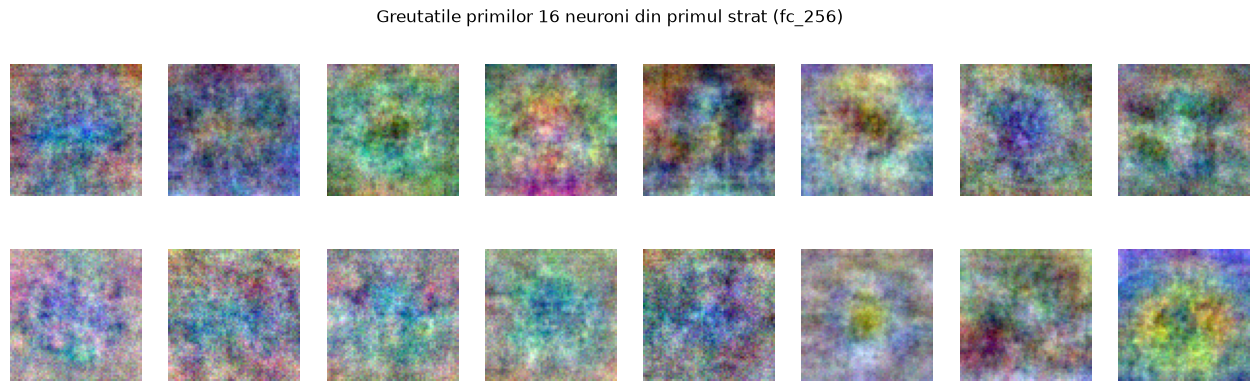

In [21]:
def load_saved_model(name):
    cfg = json.loads((lab4_common.OUT_DIR / "runs" / name / "config.json").read_text())
    model = lab4_common.build_model(cfg)
    model.load_state_dict(torch.load(lab4_common.OUT_DIR / "models" / f"{name}.pt", map_location="cpu"))
    return cfg, model.eval()


cfg_fc, model_fc = load_saved_model("fc_256")
W = model_fc.classifier[0].weight.detach().reshape(-1, 3, 64, 64)   # (neuroni, 3, 64, 64)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, w in zip(axes.ravel(), W[:16]):
    w = (w - w.min()) / (w.max() - w.min())
    ax.imshow(w.permute(1, 2, 0).numpy())
    ax.axis("off")
fig.suptitle("Greutatile primilor 16 neuroni din primul strat (fc_256)")
plt.show()

**Interpretare - greutatile primului strat**

Fiecare imagine este "sablonul" unui neuron: zonele luminoase sunt pixelii care il activeaza, cele intunecate pixelii care il inhiba.
Sabloanele arata ca **pete de culoare neclare**, aproape zgomot: cateva au o pata galbena sau verde in centru (unde e de obicei floarea),
altele culori diferite la margini (fundalul). Nu se vad margini, petale sau alte forme clare.

Asta arata ce invata o retea fully connected: "ce culoare e in ce loc din poza", pentru toata imaginea deodata.
Un astfel de sablon functioneaza doar daca floarea are aproape aceeasi pozitie si marime ca in pozele de antrenare.
Filtrele unei retele convolutionale, din contra, sunt mici (3 x 3) si cauta tipare locale (margini, texturi) oriunde in imagine.

### 6.3 Ce se intampla daca mutam imaginea cu cativa pixeli

Luam imaginile de validare din fold-ul 0 si le mutam la dreapta cu 0 - 16 pixeli (ce iese din dreapta intra in stanga).
Floarea ramane aceeasi, doar pozitia ei se schimba. Comparam macro-F1 pentru cea mai buna retea fully connected si pentru `baseline`.

**Ce face celula:**
1. alege din jurnal reteaua fully connected cu cel mai mare macro-F1;
2. ia imaginile de validare din fold-ul 0 (pe ele modelele salvate nu au fost antrenate);
3. pentru fiecare mutare (0, 2, 4, 8, 12, 16 pixeli), `torch.roll` muta imaginile la dreapta, iar modelul face predictiile;
4. calculeaza macro-F1 pentru fiecare model si fiecare mutare si le deseneaza pe acelasi grafic.

cea mai buna retea fully connected: fc_1024_256


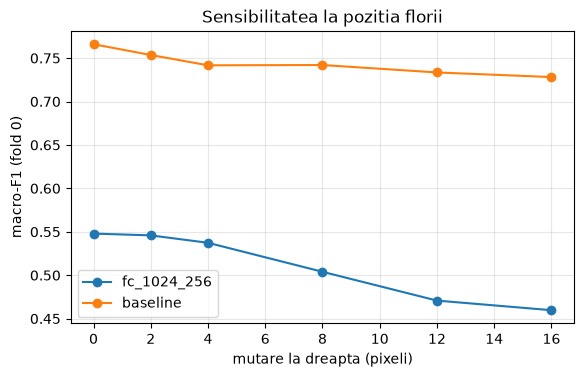

model,baseline,fc_1024_256
shift,,
0,0.766,0.548
2,0.754,0.546
4,0.742,0.537
8,0.742,0.504
12,0.733,0.471
16,0.728,0.460


In [22]:
fc_names = [*FC_SIZES, *FC_ACTIVATIONS, *FC_OTHER]
best_fc = log[log["name"].isin(fc_names)].sort_values("val_f1_mean").iloc[-1]["name"]
print("cea mai buna retea fully connected:", best_fc)

df64, X64, y64 = lab4_common.load_dataset(64)
fold = lab4_common.get_folds(df64)
val = np.where(fold == 0)[0]
shifts = [0, 2, 4, 8, 12, 16]

rows = []
for name in [best_fc, "baseline"]:
    _, model = load_saved_model(name)
    for s in shifts:
        Xs = torch.roll(X64[val], shifts=s, dims=3)
        pred = lab4_common.predict(model, Xs, "cpu").argmax(1)
        rows.append({"model": name, "shift": s, "macro_f1": f1_score(y64[val].numpy(), pred, average="macro")})
shift_res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, g in shift_res.groupby("model", sort=False):
    ax.plot(g["shift"], g["macro_f1"], marker="o", label=name)
ax.set(xlabel="mutare la dreapta (pixeli)", ylabel="macro-F1 (fold 0)", title="Sensibilitatea la pozitia florii")
ax.grid(alpha=0.3)
ax.legend()
plt.show()
shift_res.pivot(index="shift", columns="model", values="macro_f1").round(3)

**Interpretare - sensibilitatea la pozitie**

| mutare | baseline (convolutional) | fc_1024_256 (cel mai bun fully connected) |
|---|---|---|
| 0 px | 0.766 | 0.548 |
| 8 px | 0.742 (-0.02) | 0.504 (-0.04) |
| 16 px | 0.728 (-0.04) | 0.460 (-0.09) |

Floarea este aceeasi, doar mutata, dar reteaua fully connected pierde de **doua ori mai mult** decat cea convolutionala
(relativ: -16% fata de -5%). Reteaua convolutionala este aproape invarianta la pozitie: filtrele ei gasesc acelasi tipar oriunde,
iar pooling-ul pastreaza doar "a fost gasit in zona asta", nu pixelul exact. Pierderea mica pe care o are vine din faptul ca, la mutare,
o parte din floare trece in partea cealalta a imaginii. Reteaua fully connected a invatat sabloane legate de pozitia exacta a pixelilor
(sectiunea 6.2), asa ca orice mutare o incurca.

Ambele retele au fost antrenate cu augmentare (care muta pozele cu cativa pixeli), deci reteaua fully connected a vazut deja mici mutari;
chiar si asa, nu reuseste sa devina invarianta la pozitie.

## 7. Rezumatul experimentelor din Partea 1

**Ce face celula:** tabelul cu toate experimentele din Partea 1, ordonate de la cel mai bun la cel mai slab macro-F1.

In [23]:
table(ALL).sort_values("val_f1_mean", ascending=False, ignore_index=True)

,name,val_f1_mean,val_f1_std,train_f1_mean,val_acc_mean,best_epoch_mean,train_minutes_total,n_params,model_mb
0,res96,0.765,0.010,0.856,0.768,23.2,76.252,2453317,9.362
1,baseline,0.747,0.016,0.819,0.752,20.0,23.364,1142597,4.363
2,res32,0.740,0.015,0.766,0.744,21.4,7.717,356165,1.362
3,baseline_noaug,0.684,0.009,0.835,0.689,9.2,13.722,1142597,4.363
4,fc_1024_256,0.550,0.005,0.576,0.554,15.4,12.967,12847621,49.013
5,fc_256_128,0.546,0.028,0.601,0.548,18.0,4.399,3179525,12.132
6,fc_256_128_gelu,0.544,0.021,0.596,0.551,16.4,4.720,3179525,12.132
7,fc_256,0.543,0.013,0.567,0.549,15.8,3.760,3147269,12.008
8,fc_64,0.538,0.020,0.550,0.542,15.4,1.543,786821,3.004
9,fc_256_128_leaky,0.538,0.020,0.572,0.548,14.2,3.961,3179525,12.132


## Concluziile Partii 1

1. **Datele:** 5 clase, 3670 de poze, dezechilibru mic (raport 1.4). Folosim macro-F1 si fold-uri stratificate; nu e nevoie de ponderi pe clase.
   Pozele au dimensiuni si forme diferite, asa ca le taiem la un patrat din centru si le micsoram.
2. **Augmentarea este necesara:** +0.06 macro-F1 la reteaua convolutionala (0.747 fata de 0.684) si +0.05 la cea fully connected.
   Fara ea, reteaua invata pe de rost pozele de antrenare in cateva epoci.
3. **Rezolutia:** 64 x 64 este compromisul bun pentru experimente (0.747 in 23 de minute); 96 x 96 aduce inca ~0.02, dar dureaza de ~3 ori mai mult,
   deci este o optiune pentru modelul final. 32 x 32 pierde putin, dar se antreneaza de 3 ori mai repede.
4. **Retelele fully connected sunt slabe la imagini:** cel mult 0.55, cu pana la 12.8 milioane de parametri (49 MB).
   Adancimea, numarul de neuroni si functia de activare schimba foarte putin (cu exceptia lui Tanh, care se satureaza si invata prost).
   Ele invata sabloane de culoare legate de pozitie, se confunda mult (mai ales daisy -> dandelion) si sunt de doua ori mai sensibile la mutarea florii.
5. **Pentru restul echipei:** reteaua convolutionala de baza (`baseline`, 0.747 ± 0.016) cu 64 x 64 si augmentare ramane punctul de plecare.
   Confuziile principale care raman de rezolvat sunt **roses <-> tulips** si **daisy -> dandelion**.